# Project 1: Deep Neural Networks for Estimating the m-Height of Analog Codes

## The Model

- **One network per setting** (a mixture of experts). Each test sample is sent to the network of its $(k, m)$.
- **Inputs and outputs:** the matrix $P$ (zero-padded to $6 \times 5$) and $(n, k, m)$ go in. The network outputs $z = \log_2 \hat y \in [0, 100]$, and the only post-processing is $\hat y = 2^z$. Predicting the logarithm makes the training loss (mean squared error) equal to the grading cost, and guarantees every prediction is finite and $\ge 1$.
- **Network:** each network treats $P$ as a grid. Every entry repeatedly exchanges information with the other entries of its row and its column, so the prediction does not depend on the order of the rows and columns of $P$, just like the m-height (section 4).
- **Training data:** millions of new data were generated offline and we generated two kinds of data:
  - independent random matrices, sampled with the same per-matrix scales as the provided data;
  - **augmented provided** matrices, made by adding small integer noise ($\pm 2$) to every entry of provided training matrices. The provided matrices come in tight clusters, so these cover the neighbourhoods where training matrices lie.
- **Training phases:** each network is trained first on all of its setting's data (phase 1), then fine-tuned mainly on the provided and augmented provided rows, with a quarter of independent random rows (phase 2). Validation and test use only provided matrices, which were never used in training.

## Outline

1. Configuration.
2. Provided data and the data split.
3. Exact training-data generation, including a check against the provided labels.
4. The network.
5. Training.
6. Training and validation loss curves.
7. Validation and test performance.
8. **Final cell:** load the trained networks and predict m-heights for a test file.


In [ ]:
# Install dependencies (Google Colab only; elsewhere the project environment is used).

import sys

if "google.colab" in sys.modules:
    %pip install -q "numpy>=2,<3" "tensorflow==2.21.0" "keras==3.15.1" scipy matplotlib


## 1. Configuration

All settings can be changed through environment variables, which is how the batch runs were configured. The defaults below are the configuration used for the submitted results. TensorFlow is imported in section 4, after the data-generation code, whose worker processes are started by forking.

| Setting | Default | Environment variable |
|---|---|---|
| Output directory | `artifacts/submission` | `MHEIGHT_RUN` |
| Settings to train (`k-m` list) | all 9 | `MHEIGHT_SETTINGS` |
| Train the networks (otherwise load trained ones) | `1` | `MHEIGHT_TRAIN` |
| Networks (random seeds) averaged per setting | 1 | `MHEIGHT_SEEDS` |
| Train/validation/test split: `80-10-10` or `60-20-20` (section 2) | `80-10-10` | `MHEIGHT_SPLIT` |
| Use the augmented provided rows (section 3.4) | `1` | `MHEIGHT_AUGMENTED_DATA` |
| Phase 1 epochs / learning rate | 30 / 1e-3 | `MHEIGHT_PHASE1_EPOCHS` / `MHEIGHT_LR` |
| Fine-tuning epochs / learning rate | 60 / 3e-4 | `MHEIGHT_FINETUNE_EPOCHS` / `MHEIGHT_FINETUNE_LR` |
| Optimiser: `adam_plateau` or `adamw_cosine` | `adam_plateau` | `MHEIGHT_OPTIMIZER` |
| Batch size | 4096 | `MHEIGHT_BATCH` |
| Network width / row-column blocks (section 4) | 192 / 5 | `MHEIGHT_WIDTH` / `MHEIGHT_BLOCKS` |
| Dropout inside each block | 0 | `MHEIGHT_DROPOUT` |
| Share of independent random rows in fine-tuning (section 5) | 0.25 | `MHEIGHT_FINETUNE_RANDOM` |
| TF32 matrix multiplications during GPU training (section 4) | `1` | `MHEIGHT_TF32` |
| Cap on generated rows per setting (0 = all; for quick tests) | 0 | `MHEIGHT_MAX_ROWS` |


In [2]:
import hashlib
import json
import math
import multiprocessing as mp
import os
import pickle
import time
from itertools import combinations, product
from pathlib import Path

import numpy as np

N = 9
SETTINGS_ALL = [(9, k, m) for k in (4, 5, 6) for m in range(2, 9 - k + 1)]
_chosen = os.environ.get("MHEIGHT_SETTINGS", "all")
SETTINGS = SETTINGS_ALL if _chosen == "all" else [(9, *map(int, s.split("-"))) for s in _chosen.split(",")]
RUN_DIR = Path("artifacts") / os.environ.get("MHEIGHT_RUN", "submission")
RUN_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = Path("data")
TRAIN = os.environ.get("MHEIGHT_TRAIN", "1") == "1"
SEEDS = int(os.environ.get("MHEIGHT_SEEDS", 1))
AUGMENTED_DATA = os.environ.get("MHEIGHT_AUGMENTED_DATA", "1") == "1"
SPLIT = os.environ.get("MHEIGHT_SPLIT", "80-10-10")
if SPLIT not in ("60-20-20", "80-10-10"):
    raise ValueError("MHEIGHT_SPLIT must be 60-20-20 or 80-10-10")
PHASE1_EPOCHS = int(os.environ.get("MHEIGHT_PHASE1_EPOCHS", 30))
FINETUNE_EPOCHS = int(os.environ.get("MHEIGHT_FINETUNE_EPOCHS", 60))
LEARNING_RATE = float(os.environ.get("MHEIGHT_LR", 1e-3))
FINETUNE_LEARNING_RATE = float(os.environ.get("MHEIGHT_FINETUNE_LR", 3e-4))
OPTIMIZER = os.environ.get("MHEIGHT_OPTIMIZER", "adam_plateau")
BATCH_SIZE = int(os.environ.get("MHEIGHT_BATCH", 4096))
WIDTH = int(os.environ.get("MHEIGHT_WIDTH", 192))
NUM_BLOCKS = int(os.environ.get("MHEIGHT_BLOCKS", 5))
DROPOUT = float(os.environ.get("MHEIGHT_DROPOUT", 0))
FINETUNE_RANDOM = float(os.environ.get("MHEIGHT_FINETUNE_RANDOM", 0.25))
TF32 = os.environ.get("MHEIGHT_TF32", "1") == "1"
MAX_ROWS = int(os.environ.get("MHEIGHT_MAX_ROWS", 0))
SEED = 636
MAX_LOG2_HEIGHT = 100.0
print(f"Run directory: {RUN_DIR}; settings: {SETTINGS}; train: {TRAIN}; seeds: {SEEDS}; network width {WIDTH}, {NUM_BLOCKS} blocks; "
      f"split: {SPLIT}; augmented provided data: {AUGMENTED_DATA}; optimiser: {OPTIMIZER}; epochs {PHASE1_EPOCHS}+{FINETUNE_EPOCHS}")


Run directory: artifacts/submission_v8_1seed; settings: [(9, 4, 2), (9, 4, 3), (9, 4, 4), (9, 4, 5), (9, 5, 2), (9, 5, 3), (9, 5, 4), (9, 6, 2), (9, 6, 3)]; train: False; seeds: 1; network width 192, 5 blocks; split: 80-10-10; augmented provided data: True; optimiser: adam_plateau; epochs 30+60


## 2. The Provided Data and the Split

The provided training set consists of two pickled lists: 3,833,203 samples `[n, k, m, P]` and their m-heights. The test set will have the same format.
- **Matrix-level split:** the same matrix $P$ appears once for each $m$ with a finite m-height. A random split of rows would put the same matrix in both training and evaluation and make the results look better than they are. Instead, a seeded hash of $(n, k, P)$ assigns each distinct matrix, with all its rows, to **training, validation or test** in the proportions 80/10/10% (60/20/20% with `MHEIGHT_SPLIT=60-20-20`). The 80% gives the networks as many provided rows as possible, while about 383,000 rows each remain for validation and test, enough for stable estimates.
- Training rows are used to fit the networks, and as seeds for the augmented provided data. Validation rows choose the best epoch of every training phase. Test rows are used only for the final report in section 7.


In [3]:
NUMPY_MAJOR = int(np.__version__.split(".")[0])


class NumpyCompatUnpickler(pickle.Unpickler):
    # Pickles written with NumPy 2 reference numpy._core; NumPy 1.x only provides numpy.core.
    def find_class(self, module, name):
        if NUMPY_MAJOR < 2 and module.startswith("numpy._core"):
            module = "numpy.core" + module[len("numpy._core"):]
        return super().find_class(module, name)


def load_pickle(path):
    with open(path, "rb") as file:
        return NumpyCompatUnpickler(file).load()


features = load_pickle(DATA_DIR / "CSCE-636-Project-1-Train-n_k_m_P")
labels = np.asarray(load_pickle(DATA_DIR / "CSCE-636-Project-1-Train-mHeights"), dtype=np.float64)
if len(features) != len(labels) or not np.isfinite(labels).all() or labels.min() < 1:
    raise ValueError("Expected aligned lists of samples and finite m-heights >= 1")
print(f"Provided data: {len(features):,} samples")
for index in range(3):
    n, k, m, P = features[index]
    print(f"sample {index}: n={n}, k={k}, m={m}, m-height={labels[index]:.4f}\n{P}")


def matrix_partitions(samples, seed):
    """0/1/2 = train/validation/test, decided per distinct matrix by a keyed hash."""
    parts, cache, key = np.empty(len(samples), dtype=np.uint8), {}, int(seed).to_bytes(8, "little")
    for i, (n, k, m, P) in enumerate(samples):
        ident = (int(n), int(k), id(P))
        if ident not in cache:
            payload = bytes((int(n), int(k))) + np.asarray(P, dtype="<f8").tobytes(order="C")
            bucket = int.from_bytes(hashlib.blake2b(payload, digest_size=8, key=key).digest(), "little") % 10
            train_cut, validation_cut = (6, 8) if SPLIT == "60-20-20" else (8, 9)
            cache[ident] = 0 if bucket < train_cut else (1 if bucket < validation_cut else 2)
        parts[i] = cache[ident]
    return parts


partition = matrix_partitions(features, SEED)
setting_of = np.array([SETTINGS_ALL.index((int(n), int(k), int(m))) for n, k, m, _ in features], dtype=np.int8)
provided_P = np.zeros((len(features), 6, 5), dtype=np.float32)
for i, (n, k, m, P) in enumerate(features):
    provided_P[i, :k, :n - k] = P
print("\n(n, k, m)      train   validation      test")
for g, s in enumerate(SETTINGS_ALL):
    c = [int(np.sum((setting_of == g) & (partition == p))) for p in (0, 1, 2)]
    print(f"{str(s):12s} {c[0]:8,d} {c[1]:12,d} {c[2]:9,d}")


Provided data: 3,833,203 samples
sample 0: n=9, k=4, m=4, m-height=415.9635
[[  7.  29.  32.  33. -42.]
 [ 24.  38.  -3.  26.  17.]
 [ 28. -35. -20.  32. -29.]
 [-32. -14.   1. -47. -18.]]
sample 1: n=9, k=4, m=3, m-height=176.9246
[[  99.   29.  -98.   81.  -22.]
 [  24.   -3.  -48.   52. -100.]
 [ -34.   38.  -70.   55.   21.]
 [ -78.  -37.   59.  -41.  -32.]]
sample 2: n=9, k=4, m=2, m-height=34.1568
[[-41.   6.  31. -45.  48.]
 [ 10. -19. -39.  40.   1.]
 [-22. -23.   3.  -8.  38.]
 [ 24.  18. -26.  22.  -8.]]



(n, k, m)      train   validation      test
(9, 4, 2)     539,423       67,337    67,138
(9, 4, 3)     537,688       67,113    66,916
(9, 4, 4)     520,240       64,871    64,707
(9, 4, 5)     386,010       47,909    47,818
(9, 5, 2)     273,209       34,067    34,328
(9, 5, 3)     266,725       33,241    33,505
(9, 5, 4)     198,438       24,608    24,784
(9, 6, 2)     201,531       25,103    25,415
(9, 6, 3)     144,778       18,027    18,274


## 3. Exact Training-Data Generation

More training data were genearted using an equivalent but much faster exact algorithm compared to the given LP algorithm.

### 3.1 Exact labels

`vertex_heights` computes all m-heights of a batch of matrices exactly, without an LP solver.
- **Vertices:** every linear program in the m-height computation has its optimum at a vertex of its feasible region. Each vertex corresponds to $k$ columns $T$ of $G$ and a sign vector $s$, giving the codeword $c = s\,G_T^{-1}G$.
- **The m-height:** the function enumerates all of these vertices. The m-height is the largest $\max_t |c_t|$ among vertex codewords with at most $m$ entries larger than 1 in magnitude.
- **Infinite cases:** rows whose m-height is infinite (some $n-m$ columns of $G$ do not span $\mathbb R^k$) are dropped, as in the provided data and the test set.

`closed_form_heights` is a faster special case for $m = n-k$: the largest $\lVert G_T^{-1} g_j \rVert_1$ over $k$-column sets $T$ and columns $j \notin T$.

The next cell checks both functions against the provided labels. They only create training labels.


In [4]:
MAX_ENTRY = 100
COLUMN_SETS = {k: list(combinations(range(N), k)) for k in (4, 5, 6)}
SIGNS = {k: np.array([(1,) + s for s in product((1, -1), repeat=k - 1)], dtype=np.float64) for k in (4, 5, 6)}


def vertex_heights(P):
    """m-heights for m = 0..n-k of a batch P (B, k, n-k) by LP vertex enumeration; inf where infinite."""
    batch, k = P.shape[0], P.shape[1]
    G = np.concatenate((np.broadcast_to(np.eye(k), (batch, k, k)), P), axis=2)
    best = np.zeros((batch, N - k + 1))
    for T in COLUMN_SETS[k]:
        block = G[:, :, T]
        ok = np.abs(np.linalg.det(block)) >= 0.5          # integer P: nonsingular => |det| >= 1
        X = np.linalg.solve(np.where(ok[:, None, None], block, np.eye(k)), G)
        C = np.abs(np.einsum("sk,bkn->bsn", SIGNS[k], X))  # |codeword| at each vertex
        above, top = (C > 1 + 1e-9).sum(axis=2), C.max(axis=2)
        for m in range(1, N - k + 1):
            best[:, m] = np.maximum(best[:, m], np.where(ok, np.where(above <= m, top, 0.0).max(axis=1), 0.0))
    best[:, 0] = 1.0
    for m in range(1, N - k + 1):                          # infinite: some n-m columns of rank < k
        for R in combinations(range(N), N - m):
            best[np.linalg.matrix_rank(G[:, :, list(R)]) < k, m] = np.inf
    return best


def closed_form_heights(P):
    """h_{n-k} = max over k-column sets T and j not in T of ||G_T^{-1} g_j||_1; inf if some G_T is singular."""
    batch, k = P.shape[0], P.shape[1]
    G = np.concatenate((np.broadcast_to(np.eye(k), (batch, k, k)), P), axis=2)
    best, singular = np.zeros(batch), np.zeros(batch, dtype=bool)
    for T in COLUMN_SETS[k]:
        rest = [j for j in range(N) if j not in T]
        block = G[:, :, T]
        bad = np.abs(np.linalg.det(block)) < 0.5
        singular |= bad
        X = np.linalg.solve(np.where(bad[:, None, None], np.eye(k), block), G[:, :, rest])
        best = np.maximum(best, np.abs(X).sum(axis=1).max(axis=1))
    best[singular] = np.inf
    return best


# Check: both algorithms reproduce the provided labels.
rng = np.random.default_rng(0)
for g, (n, k, m) in enumerate(SETTINGS_ALL):
    idx = rng.choice(np.flatnonzero(setting_of == g), size=300, replace=False)
    Pk = np.stack([features[i][3] for i in idx]).astype(np.float64)
    err = np.abs(np.log2(vertex_heights(Pk)[:, m]) - np.log2(labels[idx])).max()
    line = f"{(n, k, m)}: vertex enumeration vs provided labels, max |log2 difference| = {err:.1e}"
    if m == n - k:
        line += f"; closed form: {np.abs(np.log2(closed_form_heights(Pk)) - np.log2(labels[idx])).max():.1e}"
    print(line)


(9, 4, 2): vertex enumeration vs provided labels, max |log2 difference| = 2.0e-14


(9, 4, 3): vertex enumeration vs provided labels, max |log2 difference| = 8.9e-15


(9, 4, 4): vertex enumeration vs provided labels, max |log2 difference| = 1.9e-14


(9, 4, 5): vertex enumeration vs provided labels, max |log2 difference| = 7.2e-13; closed form: 7.2e-13


(9, 5, 2): vertex enumeration vs provided labels, max |log2 difference| = 1.2e-14


(9, 5, 3): vertex enumeration vs provided labels, max |log2 difference| = 1.3e-13


(9, 5, 4): vertex enumeration vs provided labels, max |log2 difference| = 4.4e-13; closed form: 4.4e-13


(9, 6, 2): vertex enumeration vs provided labels, max |log2 difference| = 3.6e-15


(9, 6, 3): vertex enumeration vs provided labels, max |log2 difference| = 2.4e-12; closed form: 2.4e-12


### 3.2 Sampling new matrices

The provided matrices have integer entries. Each matrix has its own scale: its largest $|P_{ij}|$ varies widely, from about 9 at the 5th percentile to 81 at the median. New matrices copy this.
- **Scale:** for each $k$, a scale $a$ is drawn from the histogram of per-matrix $\max|P_{ij}|$ in the provided data.
- **Entries:** integers drawn uniformly from $[-a, a]$.
- **Rejection:** matrices with an all-zero column are redrawn, since the specification excludes all-zero columns of $G$.

Every matrix contributes its finite rows $m = 2, 3, \dots$. Seeds depend only on the run seed and a chunk index, so the files are reproducible regardless of the number of worker processes.

### 3.3 Generating the files

Generation runs only if the files are missing; with 128 CPU cores it takes a few minutes. The files used for the results below are:
- `CSCE-636-Project-1-Train-RandomExact.npz`: 5 million matrices per $k$, about 40 million rows, all settings, by vertex enumeration;
- `CSCE-636-Project-1-Train-RandomExact-MaxM.npz`: 10 million rows for each $m = n-k$ setting, by the closed form.


In [5]:
def empirical_scales(samples):
    """Per k, the histogram of per-matrix max |P| in the provided data (every matrix has an m=2 row)."""
    counts = {k: [0] * (MAX_ENTRY + 1) for k in (4, 5, 6)}
    for n, k, m, P in samples:
        if m == 2:
            counts[k][int(np.max(np.abs(P)))] += 1
    return {str(k): row for k, row in counts.items()}


def sample_matrix(rng, k, scale_counts):
    """Integer P with a per-matrix scale drawn from the provided data; no all-zero column."""
    weights = np.asarray(scale_counts, dtype=np.float64)
    weights[0] = 0.0
    while True:
        a = int(rng.choice(MAX_ENTRY + 1, p=weights / weights.sum()))
        P = rng.integers(-a, a + 1, size=(k, N - k)).astype(np.float64)
        if np.all(np.any(P != 0, axis=0)):
            return P


def fast_chunk(task):
    k, chunk_id, size, seed, counts = task
    rng = np.random.default_rng(np.random.SeedSequence([seed, k, chunk_id]))
    P = np.stack([sample_matrix(rng, k, counts) for _ in range(size)])
    h = vertex_heights(P)
    rows = [(P[np.isfinite(h[:, m])], m, h[np.isfinite(h[:, m]), m]) for m in range(2, N - k + 1)]
    return (np.concatenate([r[0] for r in rows]), np.concatenate([np.full(len(r[0]), r[1], np.int8) for r in rows]),
            np.concatenate([r[2] for r in rows]))


def hard_chunk(task):
    k, chunk_id, size, seed, counts = task
    rng = np.random.default_rng(np.random.SeedSequence([seed, k, chunk_id]))
    P = np.stack([sample_matrix(rng, k, counts) for _ in range(size)])
    h = closed_form_heights(P)
    return P[np.isfinite(h)], h[np.isfinite(h)]


def save_rows(path, parts):
    P = np.concatenate([p[0] for p in parts]); k = np.concatenate([p[1] for p in parts])
    m = np.concatenate([p[2] for p in parts]); h = np.concatenate([p[3] for p in parts])
    padded = np.zeros((len(P), 6, 5), np.int8)
    for kk in (4, 5, 6):
        sel = k == kk
        padded[sel, :kk, :N - kk] = P[sel][:, :kk, :N - kk]
    np.savez(path, P=padded, k=k, m=m, height=h)
    print(f"wrote {len(h):,} rows to {path}")


WORKERS = max(1, (os.cpu_count() or 2) - 1)
FAST_PATH, HARD_PATH = DATA_DIR / "CSCE-636-Project-1-Train-RandomExact.npz", DATA_DIR / "CSCE-636-Project-1-Train-RandomExact-MaxM.npz"
scale_counts = empirical_scales(features)
if not FAST_PATH.exists():
    parts = []
    with mp.get_context("fork").Pool(WORKERS) as pool:
        for k in (4, 5, 6):
            tasks = [(k, c, 10_000, 638, scale_counts[str(k)]) for c in range(500)]   # 5M matrices per k
            for P, m, h in pool.imap(fast_chunk, tasks):
                big = np.zeros((len(P), 6, 5)); big[:, :k, :N - k] = P
                parts.append((big, np.full(len(P), k, np.int8), m, h))
    save_rows(FAST_PATH, parts)
if not HARD_PATH.exists():
    parts = []
    with mp.get_context("fork").Pool(WORKERS) as pool:
        for k in (4, 5, 6):
            rows, chunk = 0, 0
            while rows < 10_000_000:
                wave = [(k, c, 20_000, 637, scale_counts[str(k)]) for c in range(chunk, chunk + 2 * WORKERS)]
                chunk += len(wave)
                for P, h in pool.imap(hard_chunk, wave):
                    take = min(len(P), 10_000_000 - rows)
                    if take <= 0:
                        break
                    big = np.zeros((take, 6, 5)); big[:, :k, :N - k] = P[:take]
                    parts.append((big, np.full(take, k, np.int8), np.full(take, N - k, np.int8), h[:take]))
                    rows += take
    save_rows(HARD_PATH, parts)
generated = [dict(np.load(FAST_PATH)), dict(np.load(HARD_PATH))]   # load once into memory
for path, d in zip((FAST_PATH, HARD_PATH), generated):
    print(f"{path.name}: {len(d['height']):,} rows")


CSCE-636-Project-1-Train-RandomExact.npz: 40,363,401 rows
CSCE-636-Project-1-Train-RandomExact-MaxM.npz: 30,000,000 rows


### 3.4 Augmented provided rows

The provided matrices come in tight **clusters**. Almost every validation matrix has a training matrix that differs from it by only 1–2 in most entries. The next cell measures this against independent random matrices, which have no such neighbours. Validation and test matrices therefore lie in small neighbourhoods of training matrices. To predict them well, a network must learn how the m-height changes as every entry of a training matrix moves by a small amount. The m-height is governed by nearly cancelling minors, so it can change a lot even then.

To cover these neighbourhoods densely, new matrices are made from the **training-split** provided matrices:
- **Noise:** every entry gets independent integer noise in $\{-2, \dots, 2\}$ and is clipped to $[-100, 100]$. Zero entries are allowed, as in the provided matrices. A matrix with an all-zero column is redrawn, because the specification excludes all-zero columns of $G$.
- **Amount:** every training matrix of a given $k$ is used the same number of times, for about 10 million new matrices per $k$: about 19 variants per matrix for $k = 4$, 37 for $k = 5$ and 50 for $k = 6$.
- **Labels:** every new matrix is labelled exactly by vertex enumeration (section 3.1), for all of its $m$ at once. Infinite heights are dropped.
- **No leakage:** a new matrix equal to any validation or test matrix is dropped, so no evaluation matrix enters training.

The independent random rows (sections 3.2–3.3) stay in phase 1 of training. They keep the networks accurate away from the provided clusters, in case test matrices come from clusters not in the provided data.


In [ ]:
def nearest_training_distances(queries, train):
    """Per query: the entries that differ from the L1-nearest training matrix, their mean |difference|,
    and the smallest largest-entry difference to any training matrix."""
    out = []
    for q in queries:
        d = np.abs(train - q)
        near = d[d.sum(1).argmin()]
        out.append(((near > 0).sum(), near[near > 0].mean() if near.any() else 0.0, d.max(1).min()))
    return np.array(out)


rng = np.random.default_rng(SEED)
for k in (4, 5, 6):
    g = SETTINGS_ALL.index((9, k, 2))   # every provided matrix has an m = 2 row
    train_m = provided_P[(setting_of == g) & (partition == 0)][:, :k, :N - k].reshape(-1, k * (N - k)).astype(np.int16)
    val_m = provided_P[(setting_of == g) & (partition == 1)][:, :k, :N - k].reshape(-1, k * (N - k)).astype(np.int16)
    rand_m = generated[0]["P"][(generated[0]["k"] == k) & (generated[0]["m"] == 2)][:300, :k, :N - k].reshape(300, -1).astype(np.int16)
    print(f"k={k}: {len(train_m):,} training matrices with {k * (N - k)} entries")
    for name, q in (("validation", val_m[rng.choice(len(val_m), 300, replace=False)]), ("independent random", rand_m)):
        s = nearest_training_distances(q, train_m)
        print(f"  300 {name:18s} matrices: nearest training matrix differs in {np.median(s[:, 0]):.0f} entries, by {np.median(s[:, 1]):.1f} "
              f"on average (medians); some training matrix within ±2 in every entry: {np.mean(s[:, 2] <= 2):.0%}")

AUG_MATRICES_PER_K = 10_000_000
AUG_PATH = DATA_DIR / f"CSCE-636-Project-1-Train-AugmentedNear-{SPLIT}.npz"


def augment_chunk(task):
    """Integer noise in {-2..2} on every entry of each parent (clipped; no all-zero column); exact heights for all m."""
    seed, parents, variants = task
    rng = np.random.default_rng(seed)
    base = np.repeat(parents, variants, axis=0)
    Q = np.clip(base + rng.integers(-2, 3, size=base.shape), -MAX_ENTRY, MAX_ENTRY)
    while (bad := ~np.any(Q != 0, axis=1).all(axis=1)).any():                  # a matrix with an all-zero column
        Q[bad] = np.clip(base[bad] + rng.integers(-2, 3, size=base[bad].shape), -MAX_ENTRY, MAX_ENTRY)
    return Q.astype(np.int8), vertex_heights(Q.astype(np.float64))


def held_out_keys(k):
    rows = np.flatnonzero(np.isin(setting_of, [g for g, s in enumerate(SETTINGS_ALL) if s[1] == k]) & (partition > 0))
    return {provided_P[i, :k, :N - k].astype(np.int8).tobytes() for i in rows}


if AUGMENTED_DATA and not AUG_PATH.exists():
    parts, counts = [], {}
    with mp.get_context("fork").Pool(WORKERS) as pool:
        for k in (4, 5, 6):
            parents = provided_P[(setting_of == SETTINGS_ALL.index((9, k, 2))) & (partition == 0)][:, :k, :N - k].astype(np.int64)
            variants = math.ceil(AUG_MATRICES_PER_K / len(parents))
            held = held_out_keys(k)
            tasks = [(np.random.SeedSequence([SEED, 7, k, i]), c, variants)
                     for i, c in enumerate(np.array_split(parents, math.ceil(len(parents) / 500)))]
            for Q, h in pool.imap(augment_chunk, tasks):
                keep = np.array([q.tobytes() not in held for q in Q], dtype=bool)
                for m in range(2, N - k + 1):
                    sel = keep & np.isfinite(h[:, m])
                    big = np.zeros((sel.sum(), 6, 5), np.int8); big[:, :k, :N - k] = Q[sel]
                    parts.append((big, np.full(sel.sum(), k, np.int8), np.full(sel.sum(), m, np.int8), h[sel, m]))
                    counts[(9, k, m)] = counts.get((9, k, m), 0) + int(sel.sum())
            print(f"k={k}: {len(parents):,} training matrices x {variants} variants")
    for setting, rows in counts.items():
        print(f"{setting}: {rows:,} augmented provided rows")
    save_rows(AUG_PATH, parts)
if AUGMENTED_DATA:
    generated.append(dict(np.load(AUG_PATH)))


k=4: 539,423 training matrices with 20 entries


  300 validation         matrices: nearest training matrix differs in 15 entries, by 1.5 on average (medians); some training matrix within ±2 in every entry: 86%


  300 independent random matrices: nearest training matrix differs in 19 entries, by 28.4 on average (medians); some training matrix within ±2 in every entry: 0%
k=5: 273,209 training matrices with 20 entries


  300 validation         matrices: nearest training matrix differs in 15 entries, by 1.5 on average (medians); some training matrix within ±2 in every entry: 89%


  300 independent random matrices: nearest training matrix differs in 19 entries, by 23.3 on average (medians); some training matrix within ±2 in every entry: 0%
k=6: 201,531 training matrices with 18 entries


  300 validation         matrices: nearest training matrix differs in 13 entries, by 1.5 on average (medians); some training matrix within ±2 in every entry: 88%


  300 independent random matrices: nearest training matrix differs in 17 entries, by 17.6 on average (medians); some training matrix within ±2 in every entry: 0%


## 4. The Network

Every setting uses the same architecture. It treats $P$ as a **grid of entries** rather than a flat list of numbers.

**Why a grid.** Reordering the rows of $P$ only relabels the message symbols, and reordering its columns only relabels code coordinates, so neither changes the m-height. A network that is built to respect this does not have to learn it from data. Each training matrix then teaches it about all $k!\,(n-k)!$ reorderings of itself at once.

1. **Inputs:** the zero-padded $6 \times 5$ matrix `P` and `[n, k, m]`. A `Cropping2D` layer keeps the setting's $k \times (n-k)$ block, scaled by a fixed `Rescaling(1/100)`.
2. **Entry embedding:** a `Dense(192, SiLU)` layer, applied to every entry separately, turns each entry into a vector of 192 numbers.
3. **5 row/column blocks.** Each block lets every entry see the rest of its row and of its column:
   - **Normalise:** a `LayerNorm` of the entry vectors.
   - **Row and column summaries:** the mean over each row (`AveragePooling2D`) and over each column. Each passes through a `Dense(192)` layer and is copied back to every entry of that row or column (`UpSampling2D`).
   - **Gated update:** for every entry, its own vector and its row's and column's summaries are concatenated into $c$. A gated layer then computes `Dense(192)(c) * Dense(192, sigmoid)(c)`, followed by `Dense(192)`.
   - **Residual connection:** the update is added to the entry's vector.

   After two blocks, every entry has information from every other entry. Further blocks let the network form the products of entries that make up the minors governing the m-height.
4. **Readout:** the mean over all entries (`GlobalAveragePooling2D`), then `Dense(192, SiLU)` and `LayerNorm`, concatenated with `[n, k, m] / 10`.
5. **Output:** `Dense(1, softplus)` followed by `ReLU(max_value=100)` gives $z = \log_2 \hat y \in [0, 100]$, so every prediction $\hat y = 2^z$ is finite and $\ge 1$.

Rows and columns enter only through means. The prediction is therefore exactly the same for every reordering of the rows and columns of $P$, which the cell below checks. Each network has about 1.7 million trainable parameters.

**TF32 during training.** The network applies its layers to every entry, so each sample costs several times more arithmetic than a network on the flat list of entries. On A100 GPUs, training uses TF32 matrix multiplications, with a 10-bit mantissa and about $10^{-3}$ relative rounding error. They make training about 2.2 times faster (22 ms instead of 49 ms per batch of 4,096 rows for $k = 4$). All evaluation (section 7) and the final cell run in full float32 on the CPU, so the reported validation and test costs include any effect of the rounding. `MHEIGHT_TF32=0` trains in full float32.



In [7]:
import matplotlib.pyplot as plt
import tensorflow as tf

tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_tensor_float_32_execution(TF32)
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
print("TensorFlow", tf.__version__, "| Keras", tf.keras.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))


def const(a):
    return tf.keras.initializers.Constant(np.asarray(a, np.float32))


def rowcol_trunk(grid, k):
    """grid: (batch, k, n-k, 1) scaled entries. Returns a vector that is invariant to row and column reorderings."""
    C = N - k
    h = tf.keras.layers.Dense(WIDTH, activation="silu", name="entry_embedding")(grid)   # one vector per entry
    for b in range(NUM_BLOCKS):
        x = tf.keras.layers.LayerNormalization(name=f"block{b}_norm")(h)
        row = tf.keras.layers.AveragePooling2D(pool_size=(1, C), name=f"block{b}_row_mean")(x)       # (batch, k, 1, W)
        row = tf.keras.layers.UpSampling2D(size=(1, C))(tf.keras.layers.Dense(WIDTH, name=f"block{b}_row")(row))
        col = tf.keras.layers.AveragePooling2D(pool_size=(k, 1), name=f"block{b}_column_mean")(x)    # (batch, 1, C, W)
        col = tf.keras.layers.UpSampling2D(size=(k, 1))(tf.keras.layers.Dense(WIDTH, name=f"block{b}_column")(col))
        context = tf.keras.layers.Concatenate()([x, row, col])
        gated = tf.keras.layers.Multiply()([tf.keras.layers.Dense(WIDTH, name=f"block{b}_value")(context),
                                            tf.keras.layers.Dense(WIDTH, activation="sigmoid", name=f"block{b}_gate")(context)])
        if DROPOUT:
            gated = tf.keras.layers.Dropout(DROPOUT)(gated)
        h = tf.keras.layers.Add()([h, tf.keras.layers.Dense(WIDTH, name=f"block{b}_update")(gated)])
    pooled = tf.keras.layers.GlobalAveragePooling2D(name="mean_over_entries")(h)
    return tf.keras.layers.LayerNormalization()(tf.keras.layers.Dense(WIDTH, activation="silu")(pooled))


def build_network(k):
    matrix_input = tf.keras.Input(shape=(6, 5), name="matrix")
    parameter_input = tf.keras.Input(shape=(3,), name="parameters")
    block = tf.keras.layers.Cropping2D(((0, 6 - k), (0, 5 - (N - k))))(tf.keras.layers.Reshape((6, 5, 1))(matrix_input))
    params = tf.keras.layers.Rescaling(1 / 10)(parameter_input)
    x = tf.keras.layers.Concatenate()([rowcol_trunk(tf.keras.layers.Rescaling(1 / 100)(block), k), params])
    x = tf.keras.layers.Dense(1, activation="softplus")(x)
    output = tf.keras.layers.ReLU(max_value=MAX_LOG2_HEIGHT, name="log2_height")(x)
    return tf.keras.Model({"matrix": matrix_input, "parameters": parameter_input}, output, name=f"mheight_k{k}")


network = build_network(4)
network.summary()
# The prediction must not change when the rows and the columns of P are reordered.
rng = np.random.default_rng(SEED)
P = np.zeros((256, 6, 5), np.float32); P[:, :4, :5] = rng.integers(-100, 101, (256, 4, 5))
Q = P.copy(); Q[:, :4, :5] = P[:, :4, :5][:, rng.permutation(4)][:, :, rng.permutation(5)]
params = np.tile(np.float32([9, 4, 2]), (256, 1))
change = np.abs(network({"matrix": P, "parameters": params}).numpy() - network({"matrix": Q, "parameters": params}).numpy()).max()
print(f"largest change of the (untrained) prediction when rows and columns are reordered: {change:.1e}")


I0000 00:00:1792194081.883836  989532 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


E0000 00:00:1792194084.490778  989532 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


TensorFlow 2.21.0 | Keras 3.15.1 | GPUs: []


Model: "mheight_k4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ matrix (InputLayer) │ (None, 6, 5)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 6, 5, 1)   │          0 │ matrix[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cropping2d          │ (None, 4, 5, 1)   │          0 │ reshape[0][0]     │
│ (Cropping2D)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 4, 5, 1)   │          0 │ cropping2d[0][0]  │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ entry_embedding     │ (None, 4, 5, 192) │        384 │ rescaling_1[0][0] │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block0_norm         │ (None, 4, 5, 192) │        384 │ entry_embedding[… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block0_row_mean     │ (None, 4, 1, 192) │          0 │ block0_norm[0][0] │
│ (AveragePooling2D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block0_column_mean  │ (None, 1, 5, 192) │          0 │ block0_norm[0][0] │
│ (AveragePooling2D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block0_row (Dense)  │ (None, 4, 1, 192) │     37,056 │ block0_row_mean[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block0_column       │ (None, 1, 5, 192) │     37,056 │ block0_column_me… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 4, 5, 192) │          0 │ block0_row[0][0]  │
│ (UpSampling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 4, 5, 192) │          0 │ block0_column[0]… │
│ (UpSampling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 4, 5, 576) │          0 │ block0_norm[0][0… │
│ (Concatenate)       │                   │            │ up_sampling2d[0]… │
│                     │                   │            │ up_sampling2d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block0_value        │ (None, 4, 5, 192) │    110,784 │ concatenate_1[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block0_gate (Dense) │ (None, 4, 5, 192) │    110,784 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 4, 5, 192) │          0 │ block0_value[0][… │
│                     │                   │            │ block0_gate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block0_update       │ (None, 4, 5, 192) │     37,056 │ multiply[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 4, 5, 192) │          0 │ entry_embedding[

 Total params: 1,703,620 (6.50 MB)

 Trainable params: 1,703,620 (6.50 MB)

 Non-trainable params: 0 (0.00 B)

largest change of the (untrained) prediction when rows and columns are reordered: 1.3e-06


## 5. Training

For each setting and seed, a network is trained in two phases.
- **Loss:** the mean squared error of $\log_2$ m-heights, exactly the grading cost.
- **Model selection:** in both phases, the provided **validation** rows of the setting choose the best epoch.

**Phase 1** trains on all of the setting's data:
- the independent generated rows (sections 3.2–3.3);
- the augmented provided rows (section 3.4);
- the provided training rows.

**Phase 2 (fine-tuning)** continues from the best phase-1 weights, at a lower learning rate, so the general function learned in phase 1 is adapted rather than overwritten. Three quarters of its rows are the augmented provided and provided training rows, which share the structure of the provided clusters. The other quarter is a fixed random sample of the independent random rows (`MHEIGHT_FINETUNE_RANDOM=0.25`). Without them, the networks adapt so fully to the clusters that they become less accurate on matrices away from them, which a test set built from new clusters would contain.

**Optimization:** Adam with gradient-norm clipping at 1 and batches of 4,096 rows.
- *Learning rate:* halved after 3 epochs without validation improvement (`adam_plateau`). Alternatively, `adamw_cosine` uses AdamW with $\beta_2 = 0.95$, a warm-up and a cosine decay.
- *Stopping:* training stops after 8 epochs without improvement, and the best epoch is restored.
- *Regularization:* none (no dropout, no weight decay). Training and validation losses stay close, so the networks are limited by fitting, not by overfitting.

Each setting has one network (one random seed). With `MHEIGHT_SEEDS` > 1, several networks are trained per setting and their predictions are averaged. The settings were trained as parallel batch jobs (`MHEIGHT_SETTINGS=k-m`), each running this notebook. The run shown here loads the trained networks (`MHEIGHT_TRAIN=0`) and prints, below, the training and validation loss of every epoch of every network, from the histories those runs saved. With `MHEIGHT_TRAIN=1`, the same cell trains the networks and prints the live Keras logs instead.


In [ ]:
def rows_for(setting, data_list):
    g = SETTINGS_ALL.index(setting); k, m = setting[1], setting[2]
    Xs, ys = [], []
    for d in data_list:
        sel = np.flatnonzero((d["k"] == k) & (d["m"] == m))
        if MAX_ROWS:
            sel = sel[:MAX_ROWS]
        Xs.append(d["P"][sel].astype(np.float32)); ys.append(np.log2(d["height"][sel]))
    return Xs, ys


def make_dataset(X, params, y, training):
    ds = tf.data.Dataset.from_tensor_slices(({"matrix": X, "parameters": params}, y.astype(np.float32)))
    if training:
        ds = ds.shuffle(min(len(y), 500_000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(2)


def compile_network(network, lr, epochs, rows):
    if OPTIMIZER == "adamw_cosine":
        steps = max(1, epochs * math.ceil(rows / BATCH_SIZE)); warmup = min(2000, steps // 10)
        lr = tf.keras.optimizers.schedules.CosineDecay(lr * 0.01, steps - warmup, alpha=0.01, warmup_target=lr, warmup_steps=warmup)
        opt = tf.keras.optimizers.AdamW(lr, weight_decay=1e-5, beta_2=0.95, clipnorm=1.0)
    else:
        opt = tf.keras.optimizers.Adam(lr, clipnorm=1.0)
    network.compile(optimizer=opt, loss="mean_squared_error")


def callbacks(path):
    cb = [tf.keras.callbacks.ModelCheckpoint(str(path), monitor="val_loss", save_best_only=True),
          tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
          tf.keras.callbacks.TerminateOnNaN()]
    if OPTIMIZER == "adam_plateau":
        cb.append(tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6))
    return cb


histories = {}
for setting in SETTINGS:
    n, k, m = setting; g = SETTINGS_ALL.index(setting)
    train_rows = np.flatnonzero((setting_of == g) & (partition == 0))
    val_rows = np.flatnonzero((setting_of == g) & (partition == 1))
    gen_X, gen_y = rows_for(setting, generated[:2])
    pert_X, pert_y = rows_for(setting, generated[2:]) if AUGMENTED_DATA else ([], [])
    prov_X, prov_y = provided_P[train_rows], np.log2(labels[train_rows])
    val = make_dataset(provided_P[val_rows], np.tile(np.float32(setting), (len(val_rows), 1)), np.log2(labels[val_rows]), False)
    X1 = np.concatenate(gen_X + pert_X + [prov_X]); y1 = np.concatenate(gen_y + pert_y + [prov_y])
    near = sum(len(v) for v in pert_y) + len(prov_y)
    take = np.random.default_rng(SEED + g).permutation(sum(len(v) for v in gen_y))[:int(near * FINETUNE_RANDOM / (1 - FINETUNE_RANDOM))]
    rand_X, rand_y = np.concatenate(gen_X)[take], np.concatenate(gen_y)[take]
    X2 = np.concatenate(pert_X + [prov_X, rand_X]); y2 = np.concatenate(pert_y + [prov_y, rand_y])
    for seed in range(SEEDS):
        tag = f"k{k}_m{m}_s{seed}"
        if not TRAIN:
            # Networks trained by earlier runs of this notebook (one batch job per setting): print their logs.
            histories[tag] = h = json.loads((RUN_DIR / f"history_{tag}.json").read_text())
            print(f"===== {setting} seed {seed}: phase 1 on {h['phase1_rows']:,} rows, fine-tuning on {h['finetune_rows']:,} rows, "
                  f"{h['minutes']:.1f} min")
            for phase in ("phase1", "finetune"):
                for e, (tr, va) in enumerate(zip(h[phase]["loss"], h[phase]["val_loss"]), 1):
                    print(f"  {phase:8s} epoch {e:3d}: training loss {tr:.4f} | validation loss {va:.4f}")
            continue
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED + seed)
        t0 = time.time()
        net = build_network(k)
        compile_network(net, LEARNING_RATE, PHASE1_EPOCHS, len(y1))
        h1 = net.fit(make_dataset(X1, np.tile(np.float32(setting), (len(y1), 1)), y1, True), validation_data=val,
                     epochs=PHASE1_EPOCHS, callbacks=callbacks(RUN_DIR / f"phase1_{tag}.keras"), verbose=2)
        compile_network(net, FINETUNE_LEARNING_RATE, FINETUNE_EPOCHS, len(y2))
        h2 = net.fit(make_dataset(X2, np.tile(np.float32(setting), (len(y2), 1)), y2, True), validation_data=val,
                     epochs=FINETUNE_EPOCHS, callbacks=callbacks(RUN_DIR / f"model_{tag}.keras"), verbose=2)
        histories[tag] = {"phase1": {key: [float(v) for v in vals] for key, vals in h1.history.items()},
                          "finetune": {key: [float(v) for v in vals] for key, vals in h2.history.items()},
                          "phase1_rows": int(len(y1)), "finetune_rows": int(len(y2)), "minutes": (time.time() - t0) / 60}
        (RUN_DIR / f"history_{tag}.json").write_text(json.dumps(histories[tag], indent=1))
        print(f"{setting} seed {seed}: phase 1 on {len(y1):,} rows (best validation {min(h1.history['val_loss']):.4f}), "
              f"fine-tuning on {len(y2):,} rows (best validation {min(h2.history['val_loss']):.4f}), "
              f"{histories[tag]['minutes']:.1f} min")


===== (9, 4, 2) seed 0: phase 1 on 15,786,624 rows, fine-tuning on 14,382,670 rows, 111.3 min
  phase1   epoch   1: training loss 0.1321 | validation loss 0.0579
  phase1   epoch   2: training loss 0.0655 | validation loss 0.0451
  phase1   epoch   3: training loss 0.0512 | validation loss 0.0323
  phase1   epoch   4: training loss 0.0431 | validation loss 0.0266
  phase1   epoch   5: training loss 0.0379 | validation loss 0.0244
  phase1   epoch   6: training loss 0.0343 | validation loss 0.0222
  phase1   epoch   7: training loss 0.0317 | validation loss 0.0200
  phase1   epoch   8: training loss 0.0294 | validation loss 0.0192
  phase1   epoch   9: training loss 0.0277 | validation loss 0.0186
  phase1   epoch  10: training loss 0.0262 | validation loss 0.0177
  phase1   epoch  11: training loss 0.0249 | validation loss 0.0157
  phase1   epoch  12: training loss 0.0238 | validation loss 0.0151
  phase1   epoch  13: training loss 0.0229 | validation loss 0.0158
  phase1   epoch  14: 

===== (9, 4, 3) seed 0: phase 1 on 15,750,747 rows, fine-tuning on 14,344,329 rows, 112.0 min
  phase1   epoch   1: training loss 0.1575 | validation loss 0.0687
  phase1   epoch   2: training loss 0.0799 | validation loss 0.0566
  phase1   epoch   3: training loss 0.0641 | validation loss 0.0441
  phase1   epoch   4: training loss 0.0544 | validation loss 0.0413
  phase1   epoch   5: training loss 0.0484 | validation loss 0.0370
  phase1   epoch   6: training loss 0.0444 | validation loss 0.0353
  phase1   epoch   7: training loss 0.0415 | validation loss 0.0328
  phase1   epoch   8: training loss 0.0394 | validation loss 0.0322
  phase1   epoch   9: training loss 0.0376 | validation loss 0.0298
  phase1   epoch  10: training loss 0.0363 | validation loss 0.0300
  phase1   epoch  11: training loss 0.0351 | validation loss 0.0288
  phase1   epoch  12: training loss 0.0341 | validation loss 0.0285
  phase1   epoch  13: training loss 0.0331 | validation loss 0.0283
  phase1   epoch  14: 

===== (9, 4, 4) seed 0: phase 1 on 15,303,931 rows, fine-tuning on 13,898,902 rows, 108.8 min
  phase1   epoch   1: training loss 0.4493 | validation loss 0.2651
  phase1   epoch   2: training loss 0.3164 | validation loss 0.2089
  phase1   epoch   3: training loss 0.2638 | validation loss 0.1692
  phase1   epoch   4: training loss 0.2245 | validation loss 0.1566
  phase1   epoch   5: training loss 0.1984 | validation loss 0.1355
  phase1   epoch   6: training loss 0.1800 | validation loss 0.1260
  phase1   epoch   7: training loss 0.1667 | validation loss 0.1193
  phase1   epoch   8: training loss 0.1563 | validation loss 0.1128
  phase1   epoch   9: training loss 0.1482 | validation loss 0.1120
  phase1   epoch  10: training loss 0.1414 | validation loss 0.1048
  phase1   epoch  11: training loss 0.1359 | validation loss 0.1042
  phase1   epoch  12: training loss 0.1311 | validation loss 0.0992
  phase1   epoch  13: training loss 0.1270 | validation loss 0.0938
  phase1   epoch  14: 

===== (9, 4, 5) seed 0: phase 1 on 21,288,289 rows, fine-tuning on 10,283,556 rows, 105.8 min
  phase1   epoch   1: training loss 2.3838 | validation loss 2.1346
  phase1   epoch   2: training loss 2.2494 | validation loss 2.0114
  phase1   epoch   3: training loss 2.1535 | validation loss 1.8796
  phase1   epoch   4: training loss 2.0393 | validation loss 1.7855
  phase1   epoch   5: training loss 1.9356 | validation loss 1.6831
  phase1   epoch   6: training loss 1.8529 | validation loss 1.5814
  phase1   epoch   7: training loss 1.7760 | validation loss 1.5367
  phase1   epoch   8: training loss 1.7064 | validation loss 1.4851
  phase1   epoch   9: training loss 1.6490 | validation loss 1.4228
  phase1   epoch  10: training loss 1.5972 | validation loss 1.3898
  phase1   epoch  11: training loss 1.5583 | validation loss 1.3776
  phase1   epoch  12: training loss 1.5220 | validation loss 1.3700
  phase1   epoch  13: training loss 1.4928 | validation loss 1.3340
  phase1   epoch  14: 

===== (9, 5, 2) seed 0: phase 1 on 15,364,879 rows, fine-tuning on 13,824,902 rows, 109.1 min
  phase1   epoch   1: training loss 0.1146 | validation loss 0.0307
  phase1   epoch   2: training loss 0.0390 | validation loss 0.0205
  phase1   epoch   3: training loss 0.0239 | validation loss 0.0123
  phase1   epoch   4: training loss 0.0160 | validation loss 0.0100
  phase1   epoch   5: training loss 0.0128 | validation loss 0.0087
  phase1   epoch   6: training loss 0.0111 | validation loss 0.0072
  phase1   epoch   7: training loss 0.0100 | validation loss 0.0074
  phase1   epoch   8: training loss 0.0089 | validation loss 0.0065
  phase1   epoch   9: training loss 0.0083 | validation loss 0.0060
  phase1   epoch  10: training loss 0.0079 | validation loss 0.0062
  phase1   epoch  11: training loss 0.0072 | validation loss 0.0055
  phase1   epoch  12: training loss 0.0069 | validation loss 0.0058
  phase1   epoch  13: training loss 0.0206 | validation loss 0.0137
  phase1   epoch  14: 

===== (9, 5, 3) seed 0: phase 1 on 15,048,344 rows, fine-tuning on 13,516,332 rows, 107.0 min
  phase1   epoch   1: training loss 0.4089 | validation loss 0.2231
  phase1   epoch   2: training loss 0.2595 | validation loss 0.1559
  phase1   epoch   3: training loss 0.1937 | validation loss 0.1186
  phase1   epoch   4: training loss 0.1489 | validation loss 0.0992
  phase1   epoch   5: training loss 0.1230 | validation loss 0.0835
  phase1   epoch   6: training loss 0.1069 | validation loss 0.0780
  phase1   epoch   7: training loss 0.0961 | validation loss 0.0694
  phase1   epoch   8: training loss 0.0877 | validation loss 0.0614
  phase1   epoch   9: training loss 0.0821 | validation loss 0.0619
  phase1   epoch  10: training loss 0.0770 | validation loss 0.0557
  phase1   epoch  11: training loss 0.0737 | validation loss 0.0526
  phase1   epoch  12: training loss 0.0700 | validation loss 0.0509
  phase1   epoch  13: training loss 0.0671 | validation loss 0.0502
  phase1   epoch  14: 

===== (9, 5, 4) seed 0: phase 1 on 21,120,810 rows, fine-tuning on 10,044,697 rows, 104.1 min
  phase1   epoch   1: training loss 2.3986 | validation loss 2.1474
  phase1   epoch   2: training loss 2.2670 | validation loss 2.0520
  phase1   epoch   3: training loss 2.1907 | validation loss 1.9702
  phase1   epoch   4: training loss 2.0975 | validation loss 1.8363
  phase1   epoch   5: training loss 2.0019 | validation loss 1.7425
  phase1   epoch   6: training loss 1.9203 | validation loss 1.6815
  phase1   epoch   7: training loss 1.8495 | validation loss 1.6144
  phase1   epoch   8: training loss 1.7862 | validation loss 1.5510
  phase1   epoch   9: training loss 1.7299 | validation loss 1.5332
  phase1   epoch  10: training loss 1.6845 | validation loss 1.4630
  phase1   epoch  11: training loss 1.6404 | validation loss 1.4421
  phase1   epoch  12: training loss 1.6056 | validation loss 1.4005
  phase1   epoch  13: training loss 1.5736 | validation loss 1.3707
  phase1   epoch  14: 

===== (9, 6, 2) seed 0: phase 1 on 15,051,338 rows, fine-tuning on 13,494,608 rows, 57.2 min
  phase1   epoch   1: training loss 0.0989 | validation loss 0.0132
  phase1   epoch   2: training loss 0.0124 | validation loss 0.0090
  phase1   epoch   3: training loss 0.0087 | validation loss 0.0071
  phase1   epoch   4: training loss 0.0070 | validation loss 0.0062
  phase1   epoch   5: training loss 0.0061 | validation loss 0.0055
  phase1   epoch   6: training loss 0.0055 | validation loss 0.0077
  phase1   epoch   7: training loss 0.0051 | validation loss 0.0052
  phase1   epoch   8: training loss 0.0048 | validation loss 0.0044
  phase1   epoch   9: training loss 0.0045 | validation loss 0.0045
  phase1   epoch  10: training loss 0.0043 | validation loss 0.0037
  phase1   epoch  11: training loss 0.0041 | validation loss 0.0039
  phase1   epoch  12: training loss 0.0039 | validation loss 0.0039
  phase1   epoch  13: training loss 0.0038 | validation loss 0.0037
  phase1   epoch  14: t

===== (9, 6, 3) seed 0: phase 1 on 20,845,570 rows, fine-tuning on 9,806,176 rows, 94.4 min
  phase1   epoch   1: training loss 1.7435 | validation loss 1.2297
  phase1   epoch   2: training loss 1.0870 | validation loss 0.8617
  phase1   epoch   3: training loss 0.7981 | validation loss 0.7141
  phase1   epoch   4: training loss 0.6514 | validation loss 0.5510
  phase1   epoch   5: training loss 0.5619 | validation loss 0.4774
  phase1   epoch   6: training loss 0.5029 | validation loss 0.4627
  phase1   epoch   7: training loss 0.4572 | validation loss 0.4095
  phase1   epoch   8: training loss 0.4244 | validation loss 0.3665
  phase1   epoch   9: training loss 0.3961 | validation loss 0.3715
  phase1   epoch  10: training loss 0.3745 | validation loss 0.3417
  phase1   epoch  11: training loss 0.3579 | validation loss 0.3247
  phase1   epoch  12: training loss 0.3430 | validation loss 0.3254
  phase1   epoch  13: training loss 0.3305 | validation loss 0.3105
  phase1   epoch  14: tr

## 6. Training and Validation Loss Curves

For each setting, the training and validation loss (mean squared $\log_2$ error) per epoch. Phase 1 is followed by fine-tuning (the dashed line marks the switch).

Training loss is measured on the training mixture, which is mostly generated data, and validation loss on provided validation matrices, so the two curves need not coincide. A steadily falling validation curve with no upturn means no overfitting. The jump at the start of fine-tuning shows the network adapting to the provided data's distribution.


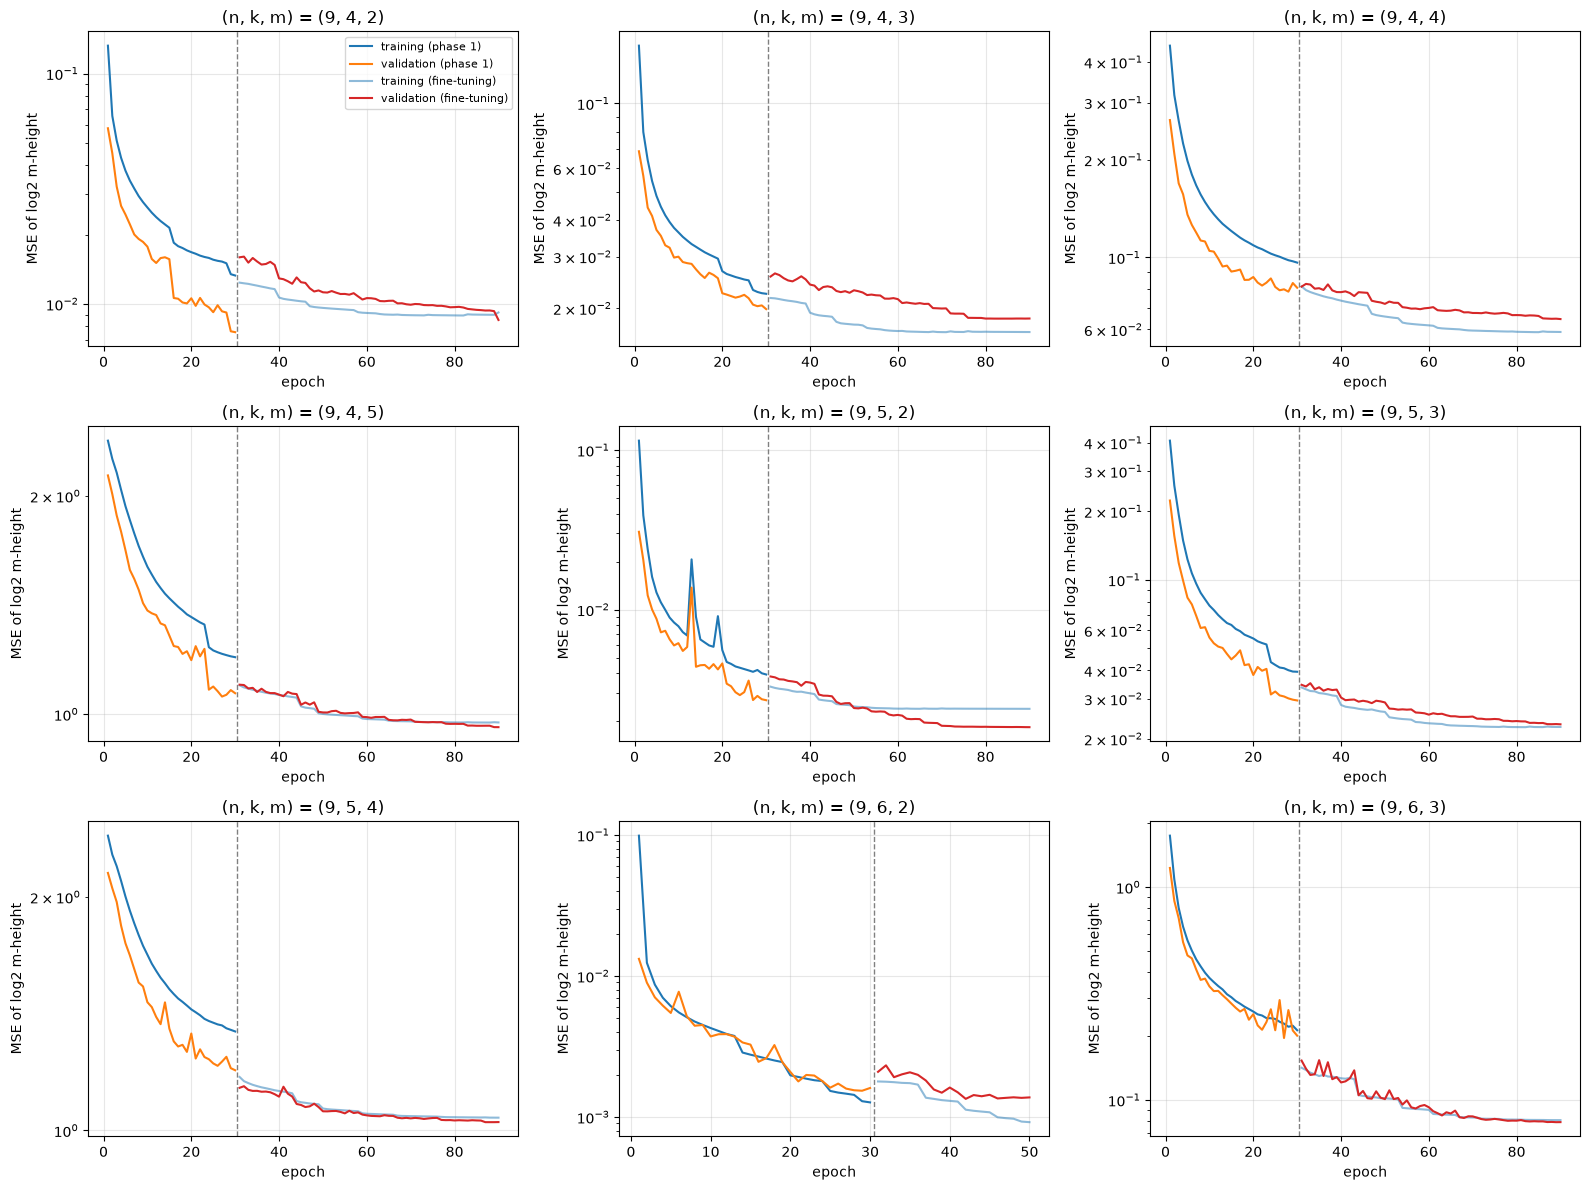

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, setting in zip(axes.ravel(), SETTINGS_ALL):
    tag = f"k{setting[1]}_m{setting[2]}_s0"
    if tag not in histories:
        ax.set_visible(False)
        continue
    h = histories[tag]; e1 = len(h["phase1"]["loss"])
    epochs1 = np.arange(1, e1 + 1); epochs2 = np.arange(e1 + 1, e1 + len(h["finetune"]["loss"]) + 1)
    ax.plot(epochs1, h["phase1"]["loss"], color="tab:blue", label="training (phase 1)")
    ax.plot(epochs1, h["phase1"]["val_loss"], color="tab:orange", label="validation (phase 1)")
    ax.plot(epochs2, h["finetune"]["loss"], color="tab:blue", alpha=0.5, label="training (fine-tuning)")
    ax.plot(epochs2, h["finetune"]["val_loss"], color="tab:red", label="validation (fine-tuning)")
    ax.axvline(e1 + 0.5, color="gray", linestyle="--", linewidth=1)
    ax.set_yscale("log"); ax.set_title(f"(n, k, m) = {setting}"); ax.set_xlabel("epoch"); ax.set_ylabel("MSE of log2 m-height")
    ax.grid(alpha=0.3)
axes.ravel()[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUN_DIR / "training_curves.png", dpi=120)
plt.show()


## 7. Final Network and Its Performance

**Per-setting networks.** Each setting's trained network is saved as `final_k{k}_m{m}.keras`. (With `MHEIGHT_SEEDS` > 1, the setting's networks would be combined there by an `Average` layer over their $\log_2$ predictions.)

**One final model.** The 9 per-setting networks are then joined into a single Keras model, `final_model_v8.keras`, which is the submitted network:
1. **Selection mask:** from the input $[n, k, m]$, a fixed `Dense` layer computes $\pm(k - k_s)$ and $\pm(m - m_s)$ for each setting $s$. `ReLU` turns these into $|k - k_s|$ and $|m - m_s|$, and a second fixed `Dense` + `ReLU` computes $\max(0,\ 1 - |k-k_s| - |m-m_s|)$. Because $k$ and $m$ are integers, this is exactly 1 for the sample's own setting and 0 for the other eight.
2. **Networks:** all 9 per-setting networks run on the sample, as sub-models.
3. **Output:** their outputs are multiplied by the mask (`Multiply`) and summed (`Dense` with weights 1), so the output is the $\log_2$ prediction of the sample's own network, still in $[0, 100]$.

The cell checks that `final_model_v8.keras` gives the same predictions as the 9 per-setting networks.

**Performance** is the cost $\sigma_{n,k,m}$ of `final_model_v8.keras` on the provided **validation** rows (used for epoch selection) and on the held-out **test** rows (used only here), together with the mean over the 9 settings. Predictions are made exactly as in the final cell (on the CPU, in batches of 1,024, with an XLA-compiled forward pass).


In [10]:
def predict_log2(network, X, params):
    @tf.function(jit_compile=True)
    def forward(batch):
        return network(batch, training=False)
    out = np.empty(len(X))
    with tf.device("/CPU:0"):
        for s in range(0, len(X), 1024):
            out[s:s + 1024] = np.asarray(forward({"matrix": X[s:s + 1024], "parameters": params[s:s + 1024]})).reshape(-1)
    return out


def combine_settings(paths):
    """One model: a fixed one-hot mask over the 9 settings selects the matching network's output."""
    ins = {"matrix": tf.keras.Input((6, 5), name="matrix"), "parameters": tf.keras.Input((3,), name="parameters")}
    W1, b1 = np.zeros((3, 4 * len(SETTINGS_ALL))), np.zeros(4 * len(SETTINGS_ALL))
    W2, b2 = np.zeros((4 * len(SETTINGS_ALL), len(SETTINGS_ALL))), np.ones(len(SETTINGS_ALL))
    for i, (n, k, m) in enumerate(SETTINGS_ALL):
        for j, (row, sign, target) in enumerate([(1, 1, k), (1, -1, k), (2, 1, m), (2, -1, m)]):
            W1[row, 4 * i + j], b1[4 * i + j] = sign, -sign * target          # +-(k - k_s), +-(m - m_s)
            W2[4 * i + j, i] = -1.0                                           # 1 - |k-k_s| - |m-m_s|
    diffs = tf.keras.layers.Dense(len(b1), activation="relu", kernel_initializer=const(W1), bias_initializer=const(b1),
                                  name="setting_differences")(ins["parameters"])
    mask = tf.keras.layers.Dense(len(b2), activation="relu", kernel_initializer=const(W2), bias_initializer=const(b2),
                                 name="setting_mask")(diffs)
    outputs = []
    for (n, k, m), path in zip(SETTINGS_ALL, paths):
        member = tf.keras.models.load_model(str(path), compile=False)
        member.name = f"network_k{k}_m{m}"
        outputs.append(member(ins))
    chosen = tf.keras.layers.Multiply()([mask, tf.keras.layers.Concatenate()(outputs)])
    out = tf.keras.layers.Dense(1, use_bias=False, kernel_initializer="ones", name="log2_height")(chosen)
    return tf.keras.Model(ins, out, name="mheight_final")


report = {}
for setting in SETTINGS:
    n, k, m = setting
    with tf.device("/CPU:0"):
        members = [tf.keras.models.load_model(str(RUN_DIR / f"model_k{k}_m{m}_s{s}.keras"), compile=False) for s in range(SEEDS)]
        if SEEDS == 1:
            final = members[0]
        else:
            ins = {"matrix": tf.keras.Input((6, 5), name="matrix"), "parameters": tf.keras.Input((3,), name="parameters")}
            for i, mem in enumerate(members):
                mem.name = f"seed_{i}"
            final = tf.keras.Model(ins, tf.keras.layers.Average(name="log2_height")([mem(ins) for mem in members]))
        final.save(RUN_DIR / f"final_k{k}_m{m}.keras")

setting_files = [RUN_DIR / f"final_k{k}_m{m}.keras" for n, k, m in SETTINGS_ALL]
if all(path.exists() for path in setting_files):
    with tf.device("/CPU:0"):
        combine_settings(setting_files).save(RUN_DIR / "final_model_v8.keras")
        evaluated = tf.keras.models.load_model(str(RUN_DIR / "final_model_v8.keras"), compile=False)
    print(f"Saved {RUN_DIR / 'final_model_v8.keras'} ({evaluated.count_params():,} parameters)")
else:
    evaluated = None
    print("Not all 9 settings are trained yet; evaluating the per-setting networks of this run")

for setting in SETTINGS:
    n, k, m = setting; g = SETTINGS_ALL.index(setting)
    with tf.device("/CPU:0"):
        own = tf.keras.models.load_model(str(RUN_DIR / f"final_k{k}_m{m}.keras"), compile=False)
    report[str(setting)] = {}
    for split, p in (("validation", 1), ("test", 2)):
        rows = np.flatnonzero((setting_of == g) & (partition == p))
        params = np.tile(np.float32(setting), (len(rows), 1))
        z = predict_log2(evaluated or own, provided_P[rows], params)
        if evaluated is not None and split == "validation":
            gap = np.abs(z - predict_log2(own, provided_P[rows], params)).max()
            print(f"{setting}: final_model_v8.keras matches the per-setting network (max |difference| {gap:.1e})")
        report[str(setting)][split] = float(np.mean((np.log2(labels[rows]) - z) ** 2))
    print(f"{setting}: validation sigma {report[str(setting)]['validation']:.4f} | test sigma {report[str(setting)]['test']:.4f}")
done = [report[str(s)] for s in SETTINGS]
print(f"\nMean over {len(done)} settings: validation {np.mean([r['validation'] for r in done]):.4f} | "
      f"test {np.mean([r['test'] for r in done]):.4f}")
(RUN_DIR / "costs.json").write_text(json.dumps(report, indent=2))


Saved artifacts/submission_v8_1seed/final_model_v8.keras (15,333,066 parameters)


I0000 00:00:1792194115.766677  989532 service.cc:153] XLA service 0x556631bbf8c0 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792194115.766706  989532 service.cc:161]   StreamExecutor [0]: Host, Default Version (Driver: 0.0.0; Runtime: 0.0.0; Toolkit: 0.0.0; DNN: 0.0.0)


I0000 00:00:1792194116.237745  989532 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


I0000 00:00:1792194118.240097  989532 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


(9, 4, 2): final_model_v8.keras matches the per-setting network (max |difference| 0.0e+00)


...

(9, 6, 2): final_model_v8.keras matches the per-setting network (max |difference| 0.0e+00)


(9, 6, 2): validation sigma 0.0013 | test sigma 0.0016


(9, 6, 3): final_model_v8.keras matches the per-setting network (max |difference| 0.0e+00)


(9, 6, 3): validation sigma 0.0785 | test sigma 0.0867

Mean over 9 settings: validation 0.2423 | test 0.2452


843

## 8. Final Cell: Predict m-Heights for a Test File

This is the cell for testing the trained model. It is **self-contained** - in a fresh session, run only this cell. On Colab it first installs the pinned TensorFlow/Keras versions. No training cells or training data are needed.

1. Place the trained model `final_model_v8.keras` next to this notebook. When run from the project folder, the cell also finds it in `artifacts/submission/`.
2. Set `TEST_INPUT_PATH` to the test file: a pickled list of samples `[n, k, m, P]`, in the same format as `CSCE-636-Project-1-Train-n_k_m_P`.
3. Run the cell. It writes `OUTPUT_PATH`: a pickled list of predicted m-heights (Python floats), one per input sample in the same order, in the same format as `CSCE-636-Project-1-Train-mHeights`.

$P$ is placed in a zero-padded $6 \times 5$ array, and $[n, k, m]$ is passed alongside it. Inside the model, each sample is handled by the network of its $(k, m)$. The model outputs $z = \log_2 \hat y \in [0, 100]$, and the only post-processing is $\hat y = 2^z$, so every prediction is finite and at least 1. The cell checks this before saving. Inside the cell, each group of samples is run through the network of its setting only (identical outputs, about 9 times faster than evaluating every network). Inference runs on the CPU in fixed batches of 1024, compiled with XLA, so repeated runs on one machine give identical results. `USE_GPU = True` makes it faster on a GPU runtime, but GPU arithmetic can differ from the CPU in the last digits, so the CPU is used for predictions that are submitted.


In [ ]:
# ===== Final cell: load the trained DNNs and predict m-heights for a test file =====
# On Google Colab, first install the package versions used for training, so the saved networks load and
# predict identically (elsewhere the project environment is used).
import sys

if "google.colab" in sys.modules:
    %pip install -q "numpy>=2,<3" "tensorflow==2.21.0" "keras==3.15.1"

import pickle
from pathlib import Path

import numpy as np
import tensorflow as tf

if "google.colab" in sys.modules and tf.__version__ != "2.21.0":
    raise RuntimeError(f"TensorFlow {tf.__version__} was already loaded: restart the runtime (Runtime > Restart session) and run this cell again.")

TEST_INPUT_PATH = "CSCE-636-Project-1-Test-n_k_m_P"   # pickled list of [n, k, m, P]
OUTPUT_PATH = "CSCE-636-Project-1-Test-mHeights"      # pickled list of predicted m-heights
MODEL_FILES = ["final_model_v8.keras", "artifacts/submission/final_model_v8.keras"]
BATCH = 1024
USE_GPU = False   # True: faster on a GPU runtime; CPU (default) reproduces submitted predictions exactly


class CompatUnpickler(pickle.Unpickler):
    # Pickles written with NumPy 2 reference numpy._core; NumPy 1.x only has numpy.core.
    def find_class(self, module, name):
        if int(np.__version__.split(".")[0]) < 2 and module.startswith("numpy._core"):
            module = "numpy.core" + module[len("numpy._core"):]
        return super().find_class(module, name)


if not Path(TEST_INPUT_PATH).exists():
    # Nothing to predict yet (e.g. a batch run before the test file is available).
    print(f"Test file {TEST_INPUT_PATH!r} not found: set TEST_INPUT_PATH and run this cell again.")
else:
    model_file = next((path for path in MODEL_FILES if Path(path).exists()), None)
    if model_file is None:
        raise FileNotFoundError(f"Trained model not found; looked for {MODEL_FILES}")
    device = "/GPU:0" if USE_GPU and tf.config.list_physical_devices("GPU") else "/CPU:0"
    with tf.device(device):
        network = tf.keras.models.load_model(model_file, compile=False)

    with open(TEST_INPUT_PATH, "rb") as file:
        samples = CompatUnpickler(file).load()

    # Inputs: P in the upper-left corner of a zero-padded 6 x 5 array, and [n, k, m].
    matrices = np.zeros((len(samples), 6, 5), dtype=np.float32)
    parameters = np.zeros((len(samples), 3), dtype=np.float32)
    for row, (n, k, m, P) in enumerate(samples):
        P = np.asarray(P, dtype=np.float64)
        if P.shape != (k, n - k):
            raise ValueError(f"Sample {row}: P has shape {P.shape}, expected {(k, n - k)}")
        matrices[row, :k, :n - k] = P
        parameters[row] = (n, k, m)

    # final_model_v8.keras selects, for every sample, the output of the network of its (k, m). Running each
    # group of samples through that network alone gives identical outputs and avoids evaluating all 9.
    log2_heights = np.full(len(samples), np.nan)
    for k, m in sorted({(int(p[1]), int(p[2])) for p in parameters}):
        rows = np.flatnonzero((parameters[:, 1] == k) & (parameters[:, 2] == m))
        setting_network = network.get_layer(f"network_k{k}_m{m}")

        @tf.function(jit_compile=True)
        def predict(batch):
            return setting_network(batch, training=False)

        with tf.device(device):
            for start in range(0, len(rows), BATCH):
                selected = rows[start:start + BATCH]
                batch = {"matrix": matrices[selected], "parameters": parameters[selected]}
                log2_heights[selected] = np.asarray(predict(batch)).reshape(-1)
    predicted_heights = np.exp2(log2_heights)

    if len(predicted_heights) != len(samples) or not np.isfinite(predicted_heights).all() \
            or np.any(predicted_heights < 1):
        raise ValueError("Every prediction must be finite and at least 1; nothing was saved")
    with open(OUTPUT_PATH, "wb") as file:
        pickle.dump(predicted_heights.tolist(), file)
    print(f"Model: {model_file} | predicted {len(predicted_heights):,} m-heights -> {OUTPUT_PATH} (TensorFlow {tf.__version__})")
    print(f"Range: {predicted_heights.min():.4f} to {predicted_heights.max():.4f}; first five: {predicted_heights[:5].tolist()}")
